# Calibration Check on Nifty

Same PIT / coverage check as we did on Sensex, run on Nifty this time.
This tells us if the pattern we found (calibrated at day 1, overconfident
after) generalizes to a second index.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
forecasts = np.load("../data/nifty_forecasts.npy")
actuals = np.load("../data/nifty_actuals.npy")

forecasts.shape, actuals.shape

((403, 30, 11), (403, 30))

## Check coverage across the same horizons we used for Sensex: day 0, 1, 15, 29

In [3]:
quantile_levels = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]

def check_coverage(day):
    day_forecasts = forecasts[:, day, :]
    day_actuals = actuals[:, day]

    lower = day_forecasts[:, 1]   # 10th percentile
    upper = day_forecasts[:, 9]   # 90th percentile

    inside = (day_actuals >= lower) & (day_actuals <= upper)
    coverage = inside.mean()

    print("day index:", day, "-> empirical coverage:", round(coverage * 100, 1), "%")
    return coverage

for d in [0, 1, 15, 29]:
    check_coverage(d)

day index: 0 -> empirical coverage: 80.6 %
day index: 1 -> empirical coverage: 75.4 %
day index: 15 -> empirical coverage: 70.7 %
day index: 29 -> empirical coverage: 75.4 %


## PIT histogram for day 15 (to compare shape against Sensex)

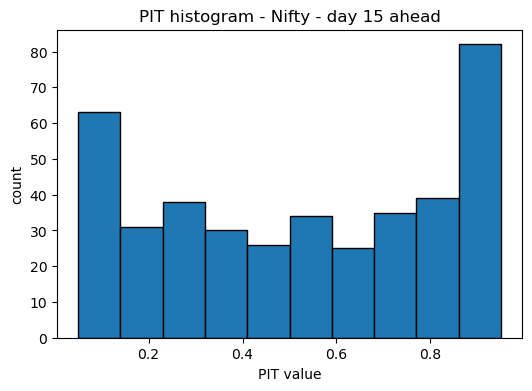

In [4]:
day = 15
day_forecasts = forecasts[:, day, :]
day_actuals = actuals[:, day]

pit_values = []
for i in range(len(day_actuals)):
    q_vals = day_forecasts[i]
    true_val = day_actuals[i]
    pit = np.interp(true_val, q_vals, quantile_levels)
    pit_values.append(pit)

pit_values = np.array(pit_values)

plt.figure(figsize=(6, 4))
plt.hist(pit_values, bins=10, edgecolor="black")
plt.xlabel("PIT value")
plt.ylabel("count")
plt.title("PIT histogram - Nifty - day 15 ahead")
plt.show()